In [1]:
# =============================================================
# FASE 3 - EDA | Consumo energético en planta siderúrgica
# Celda 1: Librerías, rutas y estilo visual común
# =============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

SEED = 42
np.random.seed(SEED)

BASE_DIR = Path("..")
DATA_PATH = BASE_DIR / "data" / "processed" / "steel_limpio.csv"
FIG_DIR = BASE_DIR / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)   # crea la carpeta si no existe

# --- Paleta fija: el mismo color significa lo mismo en TODOS los gráficos ---
# Azul para días laborales y naranja para fin de semana. Es una combinación
# distinguible para personas con daltonismo (no usamos rojo con verde).
COLOR_LABORAL = "#2a78d6"
COLOR_FINDE   = "#eb6834"
COLOR_TEXTO   = "#52514e"

# Estilo sobrio: cuadrícula suave para que destaquen los datos, no el fondo
sns.set_theme(style="whitegrid", rc={
    "grid.color": "#e6e5e1", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": COLOR_TEXTO, "xtick.color": COLOR_TEXTO, "ytick.color": COLOR_TEXTO,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
})

In [2]:
# =============================================================
# Celda 2: Carga del dataset limpio (capa plata)
# =============================================================
# Como vimos en el ETL, el CSV no guarda tipos: hay que indicar otra vez
# cuáles columnas son fechas y restaurar el ORDEN de las categorías.
df = pd.read_csv(DATA_PATH, parse_dates=["fecha_hora", "fecha"])

df["tipo_carga"] = pd.Categorical(df["tipo_carga"],
    categories=["Light_Load", "Medium_Load", "Maximum_Load"], ordered=True)
df["dia_semana"] = pd.Categorical(df["dia_semana"],
    categories=["Monday", "Tuesday", "Wednesday", "Thursday",
                "Friday", "Saturday", "Sunday"], ordered=True)
df["turno"] = pd.Categorical(df["turno"],
    categories=["Mañana", "Tarde", "Noche"], ordered=True)
df["tipo_dia"] = df["tipo_dia"].astype("category")

print("Dimensiones:", df.shape)

Dimensiones: (35040, 26)


In [3]:
# =============================================================
# Celda 3: Estadística descriptiva - variables numéricas
# =============================================================
vars_clave = ["consumo_kwh", "demanda_kw", "reactiva_inductiva_kvarh",
              "reactiva_capacitiva_kvarh", "fp_atraso_pct", "fp_adelanto_pct",
              "ratio_reactiva_activa", "co2_estimado_kg", "costo_total_usd"]

desc = df[vars_clave].describe().T
# Dos medidas extra que describe() no trae:
# - Asimetría (skew): 0 = simétrica; > 0 = cola larga hacia valores altos.
# - Coeficiente de variación (CV) = desviación / media: dispersión relativa en %.
desc["asimetria"] = df[vars_clave].skew()
desc["cv_%"] = desc["std"] / desc["mean"] * 100
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetria,cv_%
consumo_kwh,35040.0,27.39,33.44,2.45,3.20,4.57,51.24,157.18,1.20,122.12
demanda_kw,35040.0,109.55,133.78,9.80,12.80,18.28,204.95,628.72,1.20,122.12
reactiva_inductiva_kvarh,35040.0,13.04,16.31,0.00,2.30,5.00,22.64,96.91,1.44,125.09
reactiva_capacitiva_kvarh,35040.0,3.87,7.42,0.00,0.00,0.00,2.09,27.76,1.73,191.80
fp_atraso_pct,35040.0,80.58,18.92,36.94,63.32,87.96,99.02,100.00,-0.60,23.48
fp_adelanto_pct,35040.0,84.37,30.45,12.50,99.70,100.00,100.00,100.00,-1.51,36.09
ratio_reactiva_activa,35040.0,0.72,0.63,0.00,0.14,0.54,1.22,2.52,0.58,87.89
co2_estimado_kg,35040.0,11.52,14.07,1.03,1.35,1.92,21.56,66.14,1.20,122.12
costo_total_usd,35040.0,2.97,3.41,0.25,0.54,0.72,5.34,16.12,1.18,114.70


In [4]:
# =============================================================
# Celda 4: Variables categóricas + resumen anual de KPIs
# =============================================================
# Frecuencia de cada categoría (en % del total de intervalos)
for col in ["tipo_carga", "tipo_dia", "turno"]:
    print(f"\n{col}:")
    print((df[col].value_counts(normalize=True, sort=False) * 100).round(1))

# ¿Qué turno concentra el consumo? (% de la energía anual)
print("\n% de la energía anual por turno:")
print((df.groupby("turno", observed=True)["consumo_kwh"].sum()
       / df["consumo_kwh"].sum() * 100).round(1))

# Tarjeta de KPIs anuales: el "estado actual" que verá el director de planta
kpis_anuales = pd.Series({
    "Energía total (MWh)": df["consumo_kwh"].sum() / 1000,
    "Demanda máxima (kW)": df["demanda_kw"].max(),
    "Costo total estimado (USD)": df["costo_total_usd"].sum(),
    "Costo por penalización (USD)": df["costo_penalizacion_usd"].sum(),
    "% intervalos penalizados": df["penalizado"].mean() * 100,
    "Emisiones CO2 (t)": df["co2_estimado_kg"].sum() / 1000,
}).round(1)
kpis_anuales


tipo_carga:
tipo_carga
Light_Load      51.6
Medium_Load     27.7
Maximum_Load    20.8
Name: proportion, dtype: float64

tipo_dia:
tipo_dia
Weekday    71.5
Weekend    28.5
Name: proportion, dtype: float64

turno:
turno
Mañana    33.3
Tarde     33.3
Noche     33.3
Name: proportion, dtype: float64

% de la energía anual por turno:
turno
Mañana    43.9
Tarde     49.0
Noche      7.1
Name: consumo_kwh, dtype: float64


Energía total (MWh)                959.6
Demanda máxima (kW)                628.7
Costo total estimado (USD)      104056.4
Costo por penalización (USD)      8092.3
% intervalos penalizados            53.3
Emisiones CO2 (t)                  403.8
dtype: float64

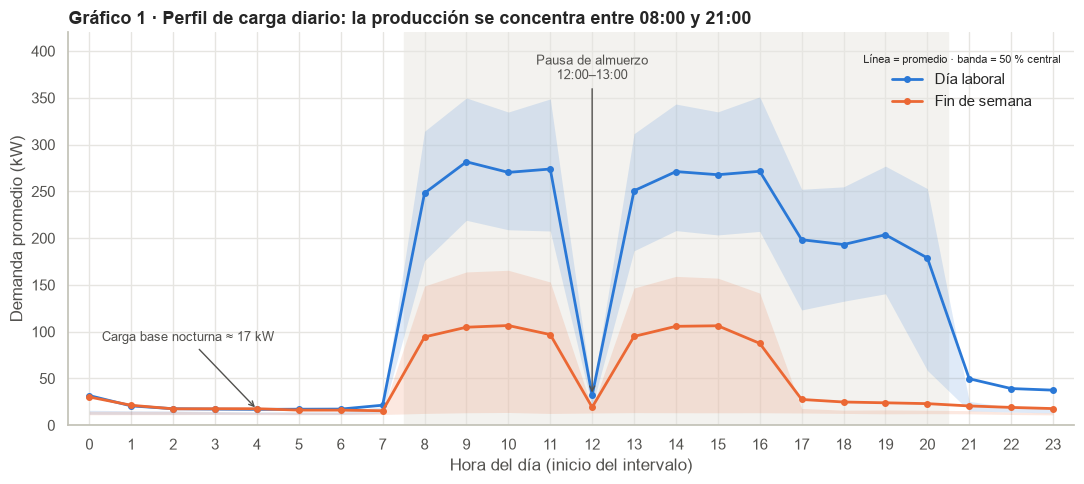

In [5]:
# =============================================================
# Celda 5: GRÁFICO 1 - Perfil de carga diario (laboral vs. fin de semana)
# =============================================================
# Pregunta: ¿a qué horas consume energía la planta y cambia el patrón
# entre días laborales y fines de semana?

# 1) Demanda por hora y tipo de día: promedio y el 50 % central (P25-P75).
#    La banda muestra la variabilidad: un promedio solo esconde
#    si todos los días se parecen o no.
perfil = (df.groupby(["tipo_dia", "hora"], observed=True)["demanda_kw"]
            .agg(promedio="mean",
                 p25=lambda s: s.quantile(0.25),
                 p75=lambda s: s.quantile(0.75))
            .reset_index())

fig, ax = plt.subplots(figsize=(11, 5))

# 2) Una línea con su banda por cada tipo de día
for tipo, color, etiqueta in [("Weekday", COLOR_LABORAL, "Día laboral"),
                              ("Weekend", COLOR_FINDE, "Fin de semana")]:
    d = perfil[perfil["tipo_dia"] == tipo]
    ax.fill_between(d["hora"], d["p25"], d["p75"], color=color, alpha=0.15, linewidth=0)
    ax.plot(d["hora"], d["promedio"], color=color, linewidth=2,
            marker="o", markersize=4, label=etiqueta)

# 3) Contexto: franja de horario productivo y anotaciones de los hallazgos
ax.axvspan(7.5, 20.5, color="#f3f2ef", zorder=0)
ax.annotate("Pausa de almuerzo\n12:00–13:00", xy=(12, 32), xytext=(12, 370),
            ha="center", fontsize=9, color=COLOR_TEXTO,
            arrowprops=dict(arrowstyle="->", color=COLOR_TEXTO))
ax.annotate("Carga base nocturna ≈ 17 kW", xy=(4, 17), xytext=(0.3, 90),
            fontsize=9, color=COLOR_TEXTO,
            arrowprops=dict(arrowstyle="->", color=COLOR_TEXTO))

# 4) Ejes, título y leyenda. El título ENUNCIA el hallazgo, no solo el tema.
ax.set_xticks(range(24))
ax.set_xlim(-0.5, 23.5)
ax.set_ylim(0, 420)
ax.set_xlabel("Hora del día (inicio del intervalo)")
ax.set_ylabel("Demanda promedio (kW)")
ax.set_title("Gráfico 1 · Perfil de carga diario: la producción se concentra entre 08:00 y 21:00")
ax.legend(frameon=False, loc="upper right", bbox_to_anchor=(1, 0.98),
          title="Línea = promedio · banda = 50 % central", title_fontsize=8)
sns.despine()
plt.tight_layout()
plt.savefig(FIG_DIR / "g1_perfil_carga.png", dpi=150, bbox_inches="tight")  # para el reporte PDF
plt.show()